<a href="https://colab.research.google.com/github/purviiii/Data-Analytics-ML-Projects/blob/main/Hierarchical-Clustering/Dendrogram_Hierarchical_Clustering_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Problem Statement**
- You are working as a data analyst at a retail company. You have been provided with customer data and are tasked with identifying distinct customer groups using Hierarchical Clustering. Your goal is to help the marketing team target each customer segment more effectively.

In [ ]:
# Dataset Link: https://drive.google.com/file/d/1kj_isJ2cHuhheK5PO3OjgNiit2FLQIDC/view?usp=sharing

In [ ]:
#print the data
#EDA(isnull,duplicates)
#apply scaling on relevant columns only

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_csv('/content/hierarchical_clustering_data (1).csv')

In [ ]:
df

,CustomerID,Annual_Income,Spending_Score,Age,Region
0,1001,67450,17.58,31,North
1,1002,57926,11.35,27,West
2,1003,69715,64.01,38,East
3,1004,82845,70.94,48,North
4,1005,56487,4.13,16,North
...,...,...,...,...,...
995,1996,55783,28.79,28,South
996,1997,86965,21.49,22,East
997,1998,69612,52.14,24,East
998,1999,51432,1.55,30,South


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      1000 non-null   int64  
 1   Annual_Income   1000 non-null   int64  
 2   Spending_Score  1000 non-null   float64
 3   Age             1000 non-null   int64  
 4   Region          1000 non-null   object 
dtypes: float64(1), int64(3), object(1)
memory usage: 39.2+ KB


In [ ]:
df.describe()

,CustomerID,Annual_Income,Spending_Score,Age
count,1000.000000,1000.00000,1000.000000,1000.000000
mean,1500.500000,60289.47500,50.861300,34.631000
std,288.819436,14688.23654,28.547316,9.700667
min,1001.000000,11380.00000,1.320000,4.000000
25%,1250.750000,50285.75000,25.475000,28.000000
50%,1500.500000,60379.00000,52.095000,35.000000
75%,1750.250000,69718.75000,74.887500,41.000000
max,2000.000000,117790.00000,99.940000,66.000000


In [ ]:
df.isnull().sum()

,0
CustomerID,0
Annual_Income,0
Spending_Score,0
Age,0
Region,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [5]:
df['Region'].value_counts()

,count
Region,
South,274
East,251
North,240
West,235


In [ ]:
df

,CustomerID,Annual_Income,Spending_Score,Age,Region
0,1001,67450,17.58,31,North
1,1002,57926,11.35,27,West
2,1003,69715,64.01,38,East
3,1004,82845,70.94,48,North
4,1005,56487,4.13,16,North
...,...,...,...,...,...
995,1996,55783,28.79,28,South
996,1997,86965,21.49,22,East
997,1998,69612,52.14,24,East
998,1999,51432,1.55,30,South


In [6]:
from sklearn.preprocessing import StandardScaler

ls=['Annual_Income', 'Spending_Score', 'Age']

x=df[ls]

In [8]:
x

,Annual_Income,Spending_Score,Age
0,67450,17.58,31
1,57926,11.35,27
2,69715,64.01,38
3,82845,70.94,48
4,56487,4.13,16
...,...,...,...
995,55783,28.79,28
996,86965,21.49,22
997,69612,52.14,24
998,51432,1.55,30


In [9]:
sc=StandardScaler()
x_scaled=sc.fit_transform(x)

In [10]:
x_scaled

array([[ 0.48774459, -1.16641275, -0.37449145],
       [-0.16098989, -1.38475612, -0.78704055],
       [ 0.64202679,  0.46082368,  0.34746948],
       ...,
       [ 0.63501086,  0.04481472, -1.09645238],
       [-0.60333363, -1.72821761, -0.47762872],
       [ 0.56526033, -1.72085772, -0.37449145]], shape=(1000, 3))

In [11]:
from scipy.cluster.hierarchy import linkage,fcluster,dendrogram
#linkage: how clusters are merged step by step
#fcluster: final cluster -> dendrogram
#dendrogram: plot the dendrogram

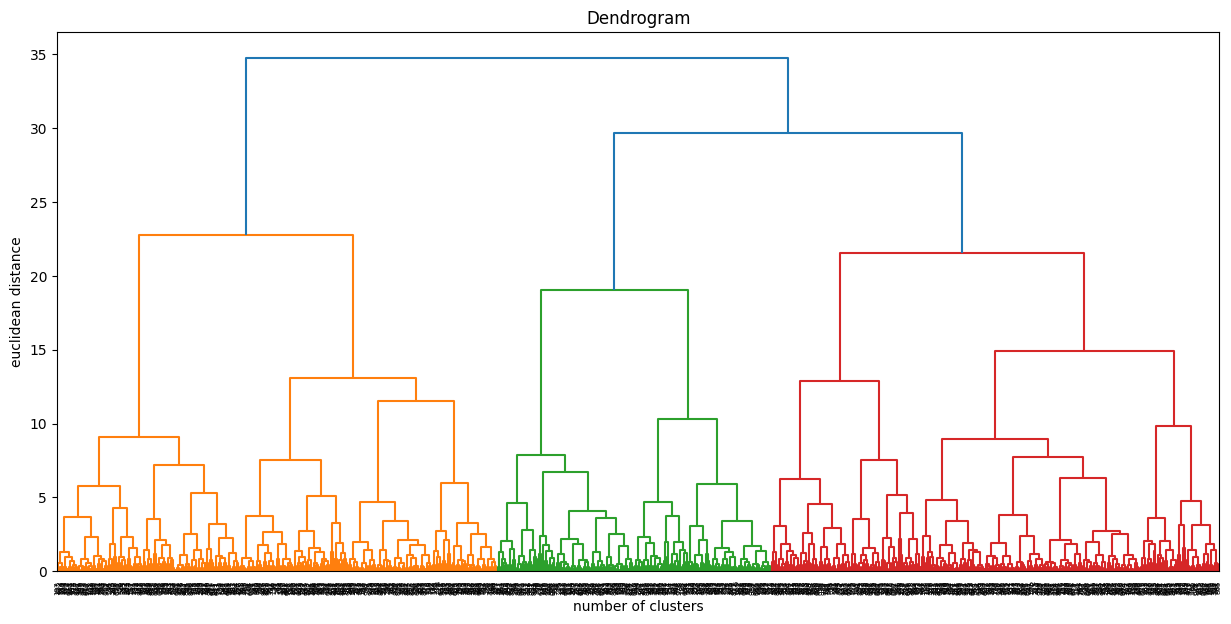

In [13]:
plt.figure(figsize=(15,7))
#ward: minimize variance(most popular in the industry)
dendrogram(linkage(x_scaled,method='ward'))
plt.xlabel("number of clusters")
plt.ylabel("euclidean distance")
plt.title("Dendrogram")
#plt.grid(True)
plt.show()

In [ ]:
# Euclidean Distance: represents that shortest path between points: sqrt of sum of squared differences

1. **Y-axis** - represents the distance(dissimilarity) at which clusters are merged
   - Small height= very similar clusters
   - Large height= very different clusters

In [ ]:
#Optimal k is decided by identifying the highest euclidean distance and intersecting a horizontal line from it
#The number of vertical lines crossed by it decides the optimal k

In [ ]:
#k=4 with distance ~=24 #number of clusters

In [14]:
link=linkage(x_scaled,method='ward')
#link has: (data points) which clusters got merged, at what distance they were merged, how many points were in each merge

cluster=fcluster(link,t=4,criterion='maxclust')
#t=4 with maxclust: FORM EXACTLY 4 CLUSTERS FROM THIS HIERARCHY

cluster

array([2, 2, 4, 4, 2, 3, 4, 4, 3, 3, 4, 3, 4, 3, 1, 3, 2, 3, 2, 3, 4, 3,
       2, 1, 1, 2, 3, 4, 3, 2, 2, 4, 4, 2, 4, 3, 2, 3, 3, 4, 2, 4, 2, 2,
       1, 1, 3, 4, 3, 1, 2, 2, 3, 4, 4, 3, 2, 3, 4, 3, 3, 2, 1, 1, 3, 4,
       3, 4, 4, 2, 4, 4, 2, 4, 3, 4, 4, 2, 4, 3, 1, 4, 4, 4, 2, 1, 3, 4,
       4, 4, 3, 4, 3, 2, 1, 1, 2, 4, 2, 3, 2, 1, 4, 3, 1, 2, 4, 4, 4, 4,
       3, 3, 4, 4, 1, 2, 4, 1, 4, 4, 2, 2, 4, 3, 4, 4, 1, 1, 3, 3, 2, 3,
       3, 3, 2, 4, 2, 3, 4, 2, 2, 4, 1, 4, 3, 4, 3, 1, 4, 2, 4, 4, 3, 4,
       4, 3, 4, 4, 1, 3, 3, 4, 4, 3, 3, 4, 2, 4, 3, 4, 3, 4, 3, 4, 4, 4,
       4, 4, 1, 4, 4, 3, 3, 4, 3, 2, 4, 2, 1, 1, 1, 4, 2, 1, 2, 2, 2, 1,
       4, 3, 4, 4, 4, 4, 1, 1, 4, 4, 2, 4, 4, 4, 4, 3, 3, 4, 3, 2, 2, 2,
       4, 3, 4, 3, 2, 3, 2, 2, 1, 2, 1, 2, 4, 2, 4, 4, 1, 2, 2, 4, 1, 4,
       4, 4, 1, 2, 1, 1, 4, 4, 3, 4, 4, 3, 3, 4, 4, 3, 2, 4, 3, 2, 3, 3,
       1, 2, 4, 1, 3, 2, 4, 1, 4, 2, 1, 2, 4, 3, 2, 2, 2, 4, 4, 1, 4, 1,
       4, 4, 3, 2, 3, 1, 1, 4, 4, 3, 2, 2, 4, 3, 2,

In [15]:
df['ClusterID']=cluster

In [ ]:
df

,CustomerID,Annual_Income,Spending_Score,Age,Region,ClusterID
0,1001,67450,17.58,31,North,2
1,1002,57926,11.35,27,West,2
2,1003,69715,64.01,38,East,4
3,1004,82845,70.94,48,North,4
4,1005,56487,4.13,16,North,2
...,...,...,...,...,...,...
995,1996,55783,28.79,28,South,2
996,1997,86965,21.49,22,East,2
997,1998,69612,52.14,24,East,4
998,1999,51432,1.55,30,South,2


In [ ]:
#pairplot is a plot with histogram in the diagonal(univariate) and scatter plot for the rest(bivariate)
#KDE: Kernel Density Estimation: smoother version of histogram
#hue: differentiates categories of a column using different colors

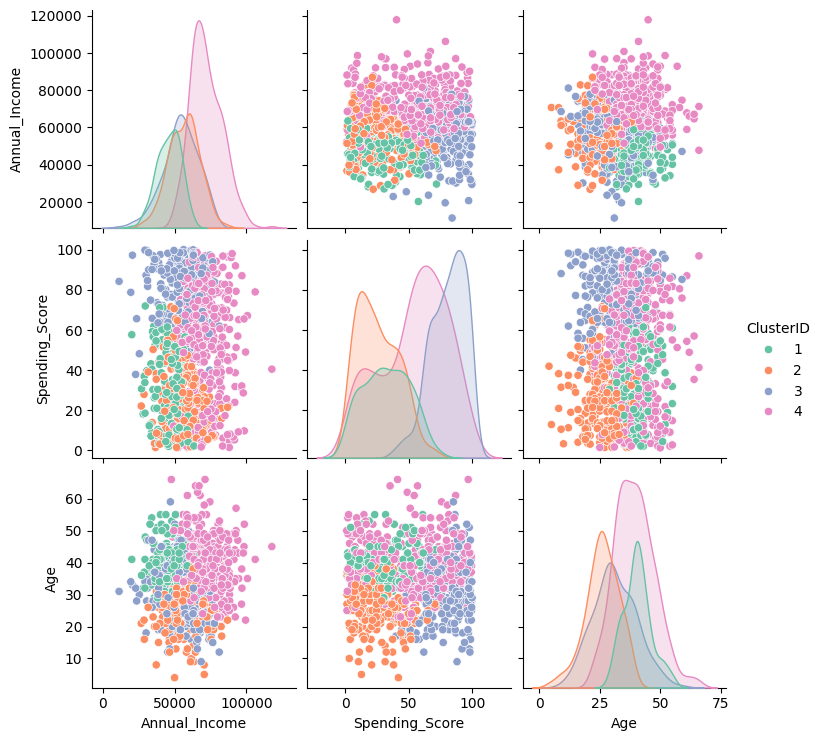

In [16]:
sns.pairplot(df,hue='ClusterID', vars=['Annual_Income','Spending_Score','Age'], palette='Set2')
plt.show()

In [17]:
#3D Visualization
import plotly.express as px

In [18]:
fig=px.scatter_3d(df,x='Annual_Income', y='Spending_Score', z='Age',color='ClusterID', hover_name='CustomerID',title='3D Visualization')
fig.update_layout(scene=dict(xaxis_title='Annual_income', yaxis_title="Spending_score", zaxis_title='Age'), width=1000, height=900)
fig.show()

In [19]:
df.groupby('ClusterID')[['Annual_Income', 'Spending_Score', 'Age']].mean()

,Annual_Income,Spending_Score,Age
ClusterID,,,
1,45932.509554,32.643312,40.445860
2,56517.369369,25.871712,25.927928
3,54319.919492,80.683432,31.199153
4,71978.477922,54.419455,39.381818


### Business Insights & Customer Personas

* **Cluster 1 (Budget-Conscious Older Customers — Avg Income: 45.9K, Spend Score: 32.6, Age: 40):** Lower income and conservative spending; target with essential discounts, value bundles, and seasonal sales.
* **Cluster 2 (Young Low-Spenders — Avg Income: 56.5K, Spend Score: 25.9, Age: 26):** Moderate income but lowest engagement; target with entry-level promotions, digital ads, and onboarding offers to boost conversion.
* **Cluster 3 (Impulsive / High-Engagement Shoppers — Avg Income: 54.3K, Spend Score: 80.7, Age: 31):** Highest spending score despite moderate income; target with flash sales, trend-driven campaigns, and instant rewards.
* **Cluster 4 (Affluent Moderate Spenders — Avg Income: 72.0K, Spend Score: 54.4, Age: 39):** Highest earning potential with room to grow wallet share; target with premium product lines, VIP memberships, and upselling.
